# Supplementary Figure S12a. AD-centered colocalization events across QTL layers

UpSet plot of the 112 AD GWAS (Bellenguez 2026 meta-analysis) colocalization events from the TransMap AD-target analysis (`AD_2026/transmap_AD_target_results_pv1e4_old.tsv`, 228 CoS), together with the AD GWAS fine-mapping layer. CoS on the same chromosome sharing at least 50% of the smaller CoS, or the same top variant, are merged into one event (228 CoS -> 112 events). Each event is flagged for overlap with an AD SuSiE 95% credible set (AD GWAS FM; 60 of 112), *cis*-eGene, *trans*-eGene, *trans*-eProgram, *trans*-biomarker colocalization, and variant overlap with AD-pathology QTL (1 event) or cell-fraction QTL (0 events). The 30 of 90 AD credible sets that overlap no colocalization event are shown as grey "AD GWAS FM only" bars (as in the author's code). Counts only; no statistical test.

Note: the 112-event count corresponds to the older 228-CoS result table; the main Figure 6a uses the updated 237-CoS table (118 events).

Input: `data/Figure_S12a_ad_coloc_membership_112.rds` (one row per colocalization event or FM-only credible set).

In [1]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(ComplexUpset)
})
mem <- readRDS("data/Figure_S12a_ad_coloc_membership_112.rds")
head(mem)
table(mem$unit_type)
colSums(mem[mem$unit_type == "Colocalization", 5:12])

,unit,unit_type,chrom,n_cos,AD_GWAS_FM,AD_GWAS,cis_eGene,trans_eGene,trans_eProgram,trans_biomarker,AD_pathology,cell_fraction
,<chr>,<chr>,<chr>,<int>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>
1,signal_1,Colocalization,chr1,3,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,FALSE,FALSE
2,signal_2,Colocalization,chr1,2,TRUE,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,FALSE
3,signal_3,Colocalization,chr1,3,FALSE,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,FALSE
4,signal_4,Colocalization,chr1,2,TRUE,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,FALSE
5,signal_5,Colocalization,chr1,2,FALSE,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,FALSE
6,signal_6,Colocalization,chr10,3,FALSE,TRUE,TRUE,TRUE,TRUE,TRUE,FALSE,FALSE



AD GWAS FM only  Colocalization 
             30             112 

AD_GWAS_FM         AD_GWAS       cis_eGene     trans_eGene  trans_eProgram 
             60             112              65             107             103 
trans_biomarker    AD_pathology   cell_fraction 
             80               1               0

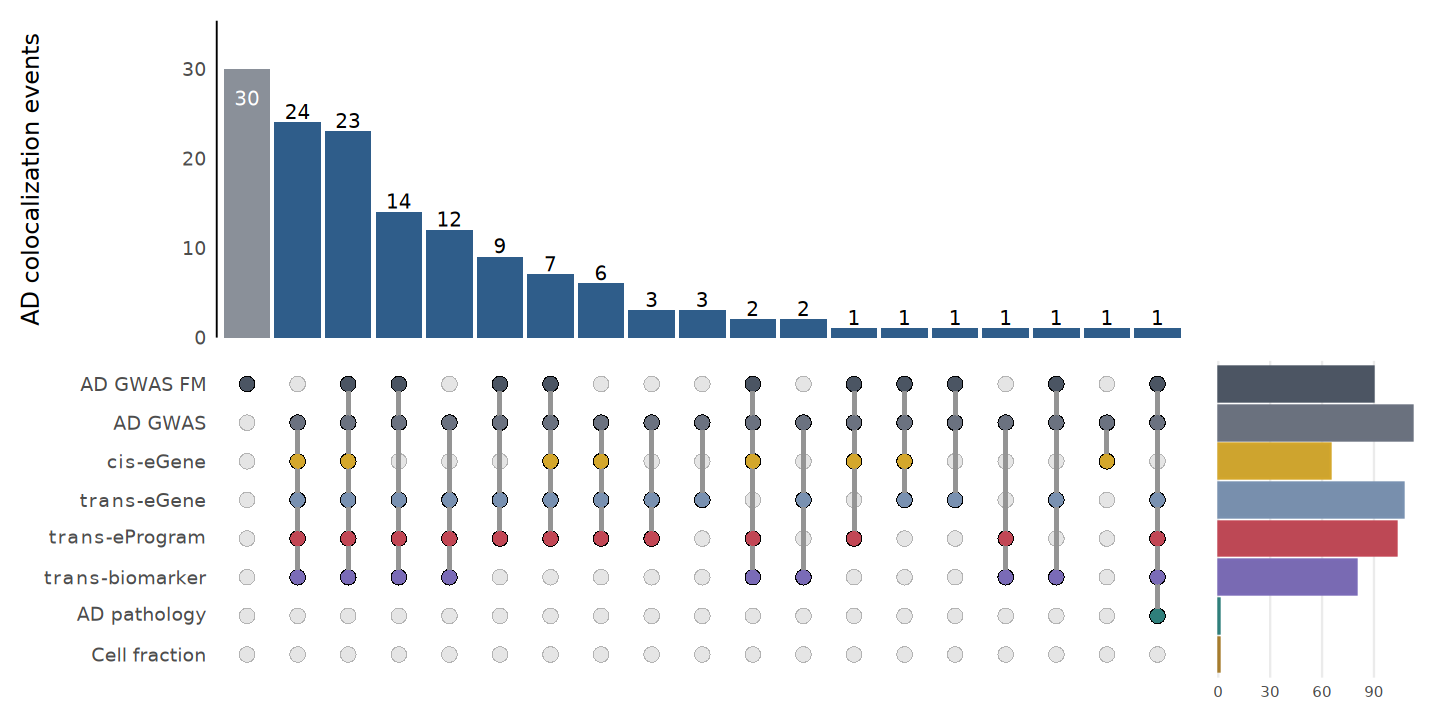

In [2]:
sets <- c("AD_GWAS_FM", "AD_GWAS", "cis_eGene", "trans_eGene", "trans_eProgram",
          "trans_biomarker", "AD_pathology", "cell_fraction")
mem$bar_group <- mem$unit_type
bar_colors <- c("AD GWAS FM only" = "#8A9099", "Colocalization" = "#2F5D8A")

set_labels <- c(
  AD_GWAS_FM      = expression(plain("AD") ~ plain("GWAS") ~ plain("FM")),
  AD_GWAS         = expression(plain("AD") ~ plain("GWAS")),
  cis_eGene       = expression(italic(cis) * plain("-eGene")),
  trans_eGene     = expression(italic(trans) * plain("-eGene")),
  trans_eProgram  = expression(italic(trans) * plain("-eProgram")),
  trans_biomarker = expression(italic(trans) * plain("-biomarker")),
  AD_pathology    = expression(plain("AD") ~ plain("pathology")),
  cell_fraction   = expression(plain("Cell") ~ plain("fraction"))
)
set_colors <- c(AD_GWAS_FM = "#4B5563", AD_GWAS = "#6B7280", cis_eGene = "#D4A72C", trans_eGene = "#7991B1",
                trans_eProgram = "#C24755", trans_biomarker = "#7A6BB7", AD_pathology = "#2F7F7B",
                cell_fraction = "#A67C2D")
sz <- 14
p_upset <- upset(
  mem, rev(sets),
  name = NULL,
  labeller = function(x) unname(set_labels[x]),
  min_size = 1, sort_sets = FALSE, sort_intersections_by = "cardinality",
  width_ratio = 0.18, height_ratio = c(1, 2), keep_empty_groups = TRUE,
  queries = lapply(sets, function(s) upset_query(set = s, fill = set_colors[[s]], color = set_colors[[s]])),
  matrix = intersection_matrix(
    geom = geom_point(shape = 16, size = 3.4),
    segment = geom_segment(linewidth = 0.8, color = "grey58")
  ) + scale_color_manual(values = c("TRUE" = "#2C3E50", "FALSE" = "#E5E5E5"), guide = "none"),
  set_sizes = upset_set_size(geom = geom_bar(alpha = 0.95), position = "right") +
    scale_fill_manual(values = set_colors, guide = "none") +
    labs(x = NULL, y = NULL) +
    theme(axis.text.y = element_blank(), axis.title = element_blank(),
          panel.grid.major.y = element_blank(), panel.grid.minor = element_blank()),
  base_annotations = list(
    "AD colocalization events" = intersection_size(
      counts = TRUE, text = list(size = sz / 3.4, vjust = -0.25),
      mapping = aes(fill = bar_group)
    ) +
      scale_fill_manual(values = bar_colors, guide = "none") +
      scale_y_continuous(expand = expansion(mult = c(0, 0.18))) +
      labs(x = NULL, y = NULL) +
      theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(),
            panel.grid = element_blank(), axis.line.y = element_line(linewidth = 0.4))
  ),
  stripes = upset_stripes(geom = geom_segment(linewidth = 0), colors = c("white", "white")),
  themes = upset_modify_themes(list(
    default = theme_minimal(base_size = sz),
    intersections_matrix = theme_minimal(base_size = sz) +
      theme(axis.title = element_blank(), axis.text.x = element_blank(), panel.grid = element_blank())
  ))
)

options(repr.plot.width = 12, repr.plot.height = 6)
p_upset